# Method F: range-Doppler map and range sectors; Method 4: fixed beds

Two methods that avoid angle estimation. Method F looks at the range-Doppler map of each frame and assigns each person a slice of the range axis. Method 4 assumes the beds do not move and steers fixed beams at their known positions.

## Why the Doppler axis is empty

The Doppler FFT over the $N_c$ chirps of one frame resolves radial velocity in steps of
$$
\Delta v = \frac{\lambda}{2\,N_c\,T_c},
$$
where $N_c T_c$ is the time the chirps of one frame span. With 64 loops of three 50 µs chirps that is 9.6 ms and $\Delta v \approx 0.26$ m/s at 60 GHz. A chest that moves 4 mm peak to peak at 15 breaths per minute reaches $\pi f A_{pp} \approx 3$ mm/s, about a hundredth of a Doppler bin. Within one frame, every person stands still: chests, beds and walls all fall in the zero-velocity column, and only gross body motion leaves it.

What does change is the zero-velocity column from frame to frame. Method F therefore removes the static part over frames, sums the power of the range-Doppler map over each person's range sector, and reads the rates from that slow-time energy. By Parseval's theorem the sum over the Doppler axis equals the sum over chirps, so the range-Doppler map is not needed to compute it (`beams.range_sectors`); it is needed to see that nothing else moves.

The energy $|z(t)-\bar z|^2$ of a breathing chest is a nonlinear function of the displacement. For a phase swing below $\pi$ it follows the chord of the arc and peaks twice per breath. For the swings of several radians that breathing produces at 60 GHz, the arc closes into full turns, the mean $\bar z$ moves towards the centre and the energy keeps only small modulations at harmonics of the breathing rate. Which harmonic dominates depends on the swing, so a rate read from the energy can be the breathing rate or a multiple of it.

sector 1: breathing set to 14   energy peak  56.1   phase of the sector's moving bin  14.0 per minute
sector 2: breathing set to 22   energy peak  88.0   phase of the sector's moving bin  22.0 per minute
sector 3: breathing set to 18   energy peak  72.3   phase of the sector's moving bin  18.1 per minute


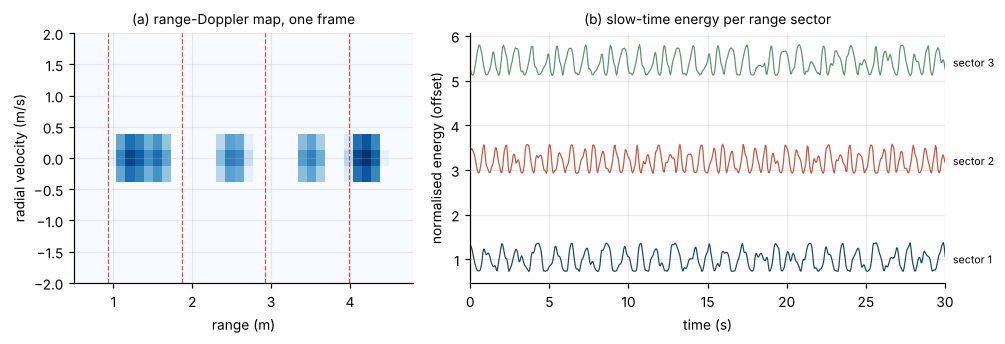

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
                     "axes.prop_cycle": plt.cycler(color=["#1b4965", "#c8553d", "#5c946e", "#8c6d9f"])})
from radar import beams, cube, simulate, vitals
from radar.spatial import steering

people = [simulate.Person(1.5, -10, rr=14, hr=80), simulate.Person(2.5, 15, rr=22, hr=95, amp=0.8),
          simulate.Person(3.5, 0, rr=18, hr=70, amp=0.7)]
clutter = [(1.2, 0, 2.0), (4.2, 0, 3.0)]
xr, _ = simulate.simulate(people, duration=1, loops=64, clutter=clutter, snr_db=20)
x, truth = simulate.simulate(people, duration=60, clutter=clutter, snr_db=20)
cfg, fs, t = truth["config"], truth["config"].frame_rate, truth["t"]
rax = cfg.range_axis()

rd = cube.doppler_fft(cube.compensate_aop(cube.range_fft(xr)))[0]          # first frame (12, 64, bins)
rd = (np.abs(rd) ** 2).sum(axis=0)
lam, tc = cfg.wavelength, 3 * 50e-6
vax = np.fft.fftshift(np.fft.fftfreq(rd.shape[0], tc)) * lam / 2

rp = cube.compensate_aop(cube.range_fft(x))
n_people, rmax = 3, int(4.0 / cfg.range_resolution)
energy = beams.range_sectors(rp, n_people, rmin_bin=int(1.0 / cfg.range_resolution), rmax_bin=rmax)

fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.2), gridspec_kw={"width_ratios": [1, 1.4]})
ax[0].imshow(10 * np.log10(rd / rd.max() + 1e-9), aspect="auto", origin="lower", vmin=-40, cmap="Blues",
             extent=[rax[0], rax[-1], vax[0], vax[-1]])
ax[0].set(xlim=(0.5, 4.8), ylim=(-2, 2), xlabel="range (m)", ylabel="radial velocity (m/s)", title="(a) range-Doppler map, one frame")
edges = np.linspace(int(1.0 / cfg.range_resolution), rmax, n_people + 1).astype(int)
for e in edges:
    ax[0].axvline(rax[e], color="#c8553d", lw=0.8, ls="--")
for k in range(n_people):
    e = energy[:, k] / energy[:, k].mean()
    ax[1].plot(t, e + 2.2 * k, lw=0.8)
    ax[1].text(30.5, 1 + 2.2 * k, f"sector {k + 1}", fontsize=7, va="center")
ax[1].set(xlim=(0, 30), xlabel="time (s)", ylabel="normalised energy (offset)", title="(b) slow-time energy per range sector")
plt.tight_layout()

moving = np.abs(cube.remove_static(rp, axis=0)).mean(axis=(0, 1, 2))
for k, p in enumerate(people):
    e = vitals.bandpass(energy[:, k] - energy[:, k].mean(), fs, (0.1, 1.5))
    b = edges[k] + int(np.argmax(moving[edges[k]:edges[k + 1]]))   # most moving bin of the sector
    z = rp[:, :, :, b].mean(axis=(1, 2))
    resp = vitals.bandpass(vitals.phase(z, vitals.circle_fit(z)[0]), fs, vitals.RR_BAND)
    print(f"sector {k + 1}: breathing set to {p.rr:2d}   energy peak {vitals.spectral_rate(e, fs, (0.1, 1.5)):5.1f}"
          f"   phase of the sector's moving bin {vitals.spectral_rate(resp, fs, vitals.RR_BAND):5.1f} per minute")

The dashed lines are the sector edges. All three chests and both static reflectors sit at zero velocity. The energy of a sector follows each breath, but its spectral peak lands on a harmonic of the breathing rate, the fourth in all three sectors here; the phase of the most moving bin of the same sector gives the set rate. In our processing the sectors were therefore kept for localisation and the rates read from the phase. The sectors also assume one person per slice of range, which holds when the radar looks along a row of beds and fails for beds side by side.

## Method 4: fixed beds

In a ward the beds do not move. If their positions are measured once, the localisation step can be dropped and a fixed beam steered at each bed (`beams.fixed_bed_beams`). The weak point is the patient, not the bed: a patient lying off the bed axis falls on the side of the beam. The gain of a delay-and-sum beam on the AOP drops as below when the chest is displaced sideways at 2 m.

-3 dB reached at 49 cm off the axis


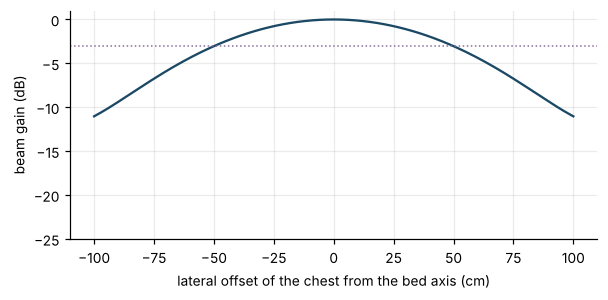

In [2]:
pos = cube.aop_positions()
offset = np.linspace(-1.0, 1.0, 201)                       # metres across, at 2 m
ang = np.degrees(np.arctan2(offset, 2.0))
gain = np.abs(steering(pos, ang).conj().T @ steering(pos, 0.0)[:, 0]) / len(pos)

fig, ax = plt.subplots(figsize=(5.6, 2.8))
ax.plot(100 * offset, 20 * np.log10(gain))
ax.axhline(-3, color="#8c6d9f", ls=":", lw=1)
ax.set(xlabel="lateral offset of the chest from the bed axis (cm)", ylabel="beam gain (dB)", ylim=(-25, 1))
plt.tight_layout()
print(f"-3 dB reached at {100 * offset[(gain >= 10 ** (-3 / 20))].max():.0f} cm off the axis")

At 2 m the beam keeps its gain within about half a metre of the axis, wider than a bed, so a patient who shifts in bed stays inside it. The neighbouring bed is the problem: with the beds 1 m apart, the next patient sits at the edge of the main lobe and leaks into the beam, which is where Methods A and B take over.